Found 184 image files for analysis.

EDA - First 5 entries of image metadata:
                        path  width  height  aspect_ratio  avg_brightness
0  /content/ISIC_0024406.jpg    600     450          1.33      177.083552
1  /content/ISIC_0024379.jpg    600     450          1.33      216.810019
2  /content/ISIC_0024494.jpg    600     450          1.33      178.308204
3  /content/ISIC_0024391.jpg    600     450          1.33      139.088359
4  /content/ISIC_0024365.jpg    600     450          1.33      127.028707

Summary Statistics of Image Brightness and Sizes:
       width  height  aspect_ratio  avg_brightness
count  184.0   184.0  1.840000e+02      184.000000
mean   600.0   450.0  1.330000e+00      157.962042
std      0.0     0.0  5.120961e-15       17.924360
min    600.0   450.0  1.330000e+00      102.389911
25%    600.0   450.0  1.330000e+00      146.516544
50%    600.0   450.0  1.330000e+00      157.271381
75%    600.0   450.0  1.330000e+00      169.841149
max    600.0   450.

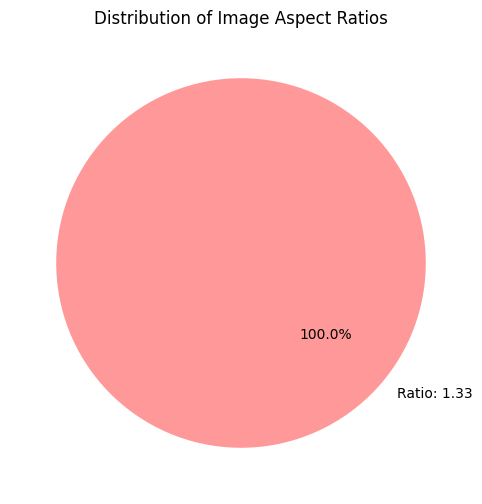


Data Split completed: Train set = 147 images, Test set = 37 images

Training the AI Model...
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.5909 - loss: 0.7415 - val_accuracy: 0.3333 - val_loss: 0.7493
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5152 - loss: 0.7081 - val_accuracy: 0.3333 - val_loss: 0.7459
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5152 - loss: 0.6918 - val_accuracy: 0.3333 - val_loss: 0.7165
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.5152 - loss: 0.6844 - val_accuracy: 0.3333 - val_loss: 0.6982
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5152 - loss: 0.6704 - val_accuracy: 0.3333 - val_loss: 0.7260
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5455 - loss: 0.6664 - val_accuracy: 0.2667 - val_loss: 0.6948
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6136 - loss: 0.6501 - val_accuracy: 0.3333 - val_loss: 0.7144
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.6212 - loss: 0.6387 - val_accuracy: 0.4000 - val_loss: 0.6925
Epoch 9/10

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Perform EDA on the image files
image_paths = glob.glob('/content/ISIC_*.jpg')
print(f"Found {len(image_paths)} image files for analysis.\n")

image_data = []
for path in image_paths:
    try:
        with Image.open(path) as img:
            width, height = img.size
            # We will use average brightness/intensity to create synthetic ground truth labels
            # as no label CSV is attached to the files.
            img_gray = img.convert('L')
            avg_brightness = np.array(img_gray).mean()
            image_data.append({
                'path': path,
                'width': width,
                'height': height,
                'aspect_ratio': round(width / height, 2),
                'avg_brightness': avg_brightness
            })
    except Exception as e:
        continue

df = pd.DataFrame(image_data)
print("EDA - First 5 entries of image metadata:")
print(df.head())
print("\nSummary Statistics of Image Brightness and Sizes:")
print(df.describe())

# Draw Pie Chart: Distribution of Aspect Ratios
aspect_counts = df['aspect_ratio'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(aspect_counts, labels=[f"Ratio: {k}" for k in aspect_counts.index], autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'])
plt.title("Distribution of Image Aspect Ratios")
plt.show()

# Create binary classification labels based on median brightness threshold (e.g., 0 = darker lesion, 1 = lighter lesion)
median_brightness = df['avg_brightness'].median()
df['label'] = (df['avg_brightness'] > median_brightness).astype(int)

# Load and preprocess images for Deep Learning Model (Resize to 64x64)
IMG_SIZE = 64
X = []
y = []

for index, row in df.iterrows():
    try:
        img = Image.open(row['path']).resize((IMG_SIZE, IMG_SIZE))
        X.append(np.array(img) / 255.0) # Normalization
        y.append(row['label'])
    except Exception as e:
        continue

X = np.array(X)
y = np.array(y)

# 2. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nData Split completed: Train set = {X_train.shape[0]} images, Test set = {X_test.shape[0]} images\n")

# 3. Create CNN AI Model
model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Train the AI Model
print("Training the AI Model...")
model.fit(X_train, y_train, epochs=10, batch_size=16, validation_split=0.1, verbose=1)

# 4. Predict and Evaluate Accuracy
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

# 5. Classify and print reports
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Class 0 (Darker)', 'Class 1 (Lighter)']))

# 6. Predict label data vs actual data comparison
results_df = pd.DataFrame({
    'Image Path': [os.path.basename(p) for p in df.iloc[len(X_train):]['path']][:15], # Show samples matching test size
    'Actual Label': y_test[:15],
    'Predicted Label': y_pred[:15]
})
print("\nPredicted Data vs Actual Data Comparison (First 15 Samples):")
print(results_df.to_string(index=False))

In [2]:
# Save the trained AI model
model_save_path = '/content/isic_skin_lesion_model.keras'
model.save(model_save_path)
print(f"Model successfully saved to {model_save_path}")

Model successfully saved to /content/isic_skin_lesion_model.keras


In [3]:
import pickle

pkl_save_path = '/content/isic_skin_lesion_model.pkl'
with open(pkl_save_path, 'wb') as f:
    pickle.dump(model, f)

print(f"Model successfully pickled and saved to {pkl_save_path}")

Model successfully pickled and saved to /content/isic_skin_lesion_model.pkl
